In [6]:
import numpy as np
import networkx as nx
import matplotlib.pyplot as plt
import time as time
import graphstate_opt as gso

def round_off(num, k):
    return int(num*10**k)/10**k

def plot_weighted_graph(in_graph, W=None):
    n = in_graph.number_of_nodes()
    if W is None:
        W = np.ones((n,n))

    arr = nx.to_numpy_array(in_graph)
    for i in range(n):
        for j in range(i, n):
            arr[i,j] = arr[i,j] * round_off(W[i,j], 3)
            arr[j,i] = arr[i,j]

    G = nx.from_numpy_array(arr)
    pos = nx.spring_layout(G, seed=42)   # nice layout
    weights = nx.get_edge_attributes(G, 'weight')

    nx.draw(G, pos, with_labels=True, node_size=800, font_size=12)
    nx.draw_networkx_edge_labels(G, pos, edge_labels=weights)
    plt.show()

    return


As a simple example, we run our algorithms for a complete graph, which is known to be LC-equivalent to a start graph (obtained by applying local complementation to any vertex of the complete graph). We input the graph as an instance of a networkx complete graph. We input the values of maximum number of iterations of `EDM-SA` and the value of initial temperature to `EDM-SAILP`.   As expected, the output graphs from `EDM-SA`and `EDM-SAILP` are both star graphs.

EDM-SAILP runtime = 0.18032598495483398
EDM-ILP runtime = 0.16030359268188477


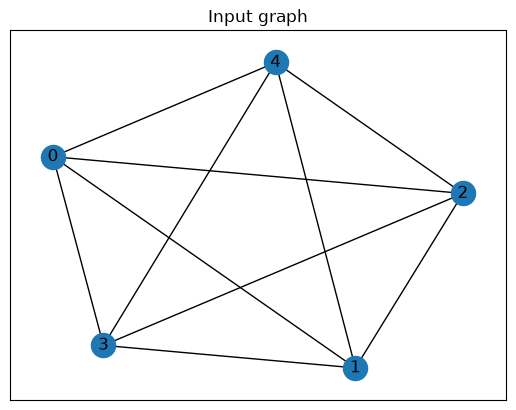

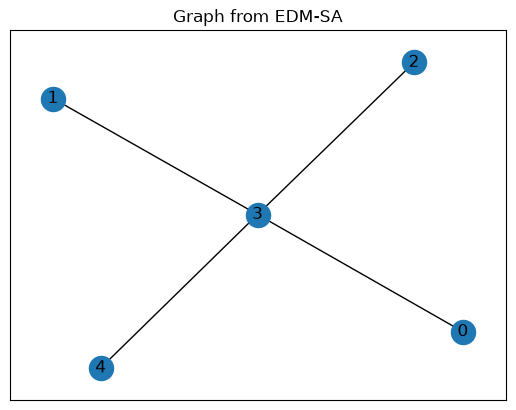

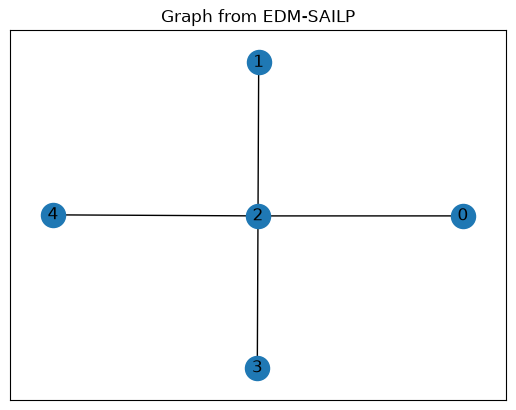

In [7]:
#parameters maximum iterations and temperature for the SA algorithm
kmax = 100
temperature = 100

# defining the input graph as networkx complete graph
G = nx.complete_graph(5)

# calling and giving the graph G as the input to SA+ILP and ILP
# the function returns graphs obtained from SA and SA+ILP.
# and the runtime of ILP and SA+ILP
output = gso.edm_sa_ilp(G, kmax, temperature)

#output graph from SA+ILP of the algorithm
gout_sailp = output[0]
# output graph from SA part
gout_sa = output[1]

#the runtimes for SA+ILP and ILP
sailp_runtime = output[4]
ilp_runtime = output[5]
print("EDM-SAILP runtime =", sailp_runtime)
print("EDM-ILP runtime =", ilp_runtime)

plt.figure()
plt.title("Input graph")
nx.draw_networkx(G)
plt.draw()
plt.show(block=False)

plt.figure()
plt.title("Graph from EDM-SA")
nx.draw_networkx(gout_sa)
plt.draw()
plt.show(block=False)


plt.figure()
plt.title("Graph from EDM-SAILP")
nx.draw_networkx(gout_sailp)
plt.draw()
plt.show(block=False)


Now we input arbitrary graph using the Erdos-Renyi graph model. 

Number of edges from EDM-SA = 7
Number of edges from EDM-SAILP = 6.999999999999967
EDM-SAILP runtime = 0.7107806205749512
EDM-ILP runtime = 0.6861817836761475


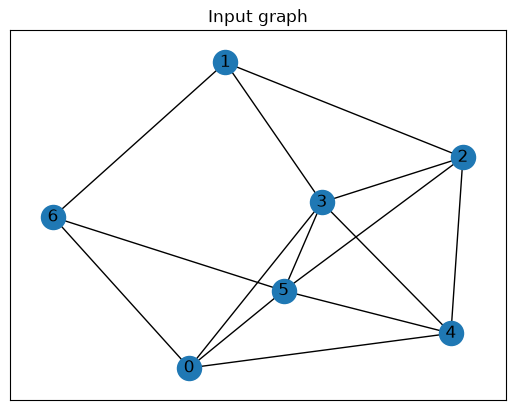

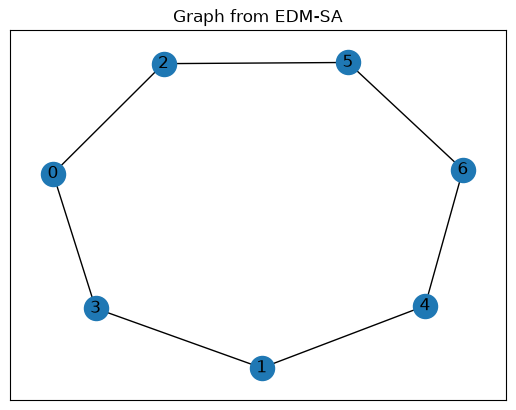

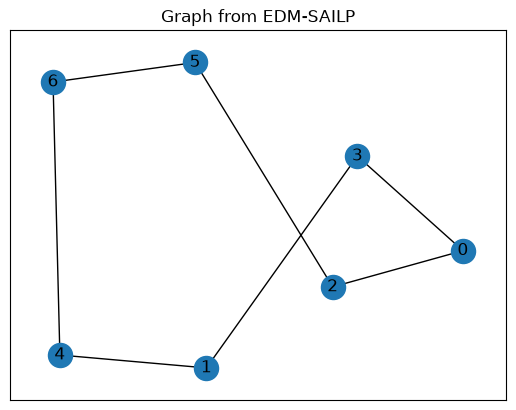

In [8]:
#parameters maximum iterations and temperature for the SA algorithm
kmax = 100
temperature = 100

# defining the input graph as networkx complete graph
prob_of_edge_inclusion = 0.6
G = nx.erdos_renyi_graph(7, prob_of_edge_inclusion)

# calling and giving the graph G as the input to SA+ILP and ILP
# the function returns graphs obtained from SA and SA+ILP.
# and the runtime of ILP and SA+ILP
output = gso.edm_sa_ilp(G, kmax, temperature)

#output graph from SA+ILP of the algorithm
gout_sailp = output[0]
# output graph from SA part
gout_sa = output[1]

#the number of output edges from SA and SA+ILP
sa_edges = output[2]
sailp_edges = output[3]
print("Number of edges from EDM-SA =", sa_edges)
print("Number of edges from EDM-SAILP =", sailp_edges)

#the runtimes for SA+ILP and ILP
sailp_runtime = output[4]
ilp_runtime = output[5]
print("EDM-SAILP runtime =", sailp_runtime)
print("EDM-ILP runtime =", ilp_runtime)

plt.figure()
plt.title("Input graph")
nx.draw_networkx(G)
plt.draw()
plt.show(block=False)

plt.figure()
plt.title("Graph from EDM-SA")
nx.draw_networkx(gout_sa)
plt.draw()
plt.show(block=False)


plt.figure()
plt.title("Graph from EDM-SAILP")
nx.draw_networkx(gout_sailp)
plt.draw()
plt.show(block=False)


As an example to show that `EDM-SA` can go up to graphs with 100 nodes, we run the following code. Here we have an Erdos-Renyi graph with 100 qubits and edge inclusion probability of 0.6. The maximum number of iterations is 1000 and the initial temperature is set to 100.

Runtime 31.68637752532959
Edges in original 2944
Edges obtianed from SA 2310


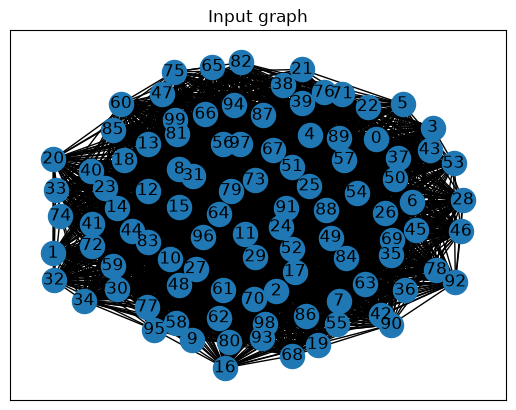

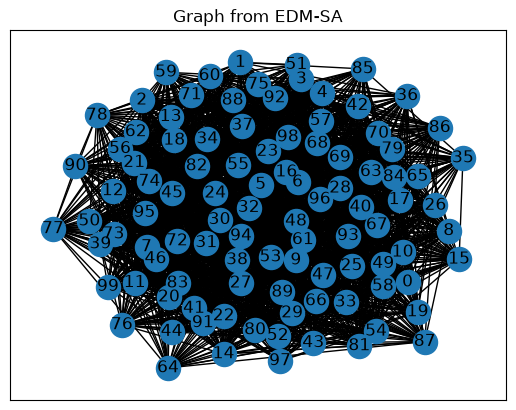

In [9]:

# Erdos-Renyi graph as an input
G = nx.erdos_renyi_graph(100, 0.6)
kmax = 1000
temp = 100


t = time.time()
gout, _, _ = gso.edm_sa(G, kmax, temp)

print("Runtime", time.time()-t)
print("Edges in original", G.number_of_edges())
print("Edges obtianed from SA", gout.number_of_edges())#

#plotting the graph
plt.figure()
plt.title("Input graph")
nx.draw_networkx(G)
plt.draw()
plt.show(block=False)

plt.figure()
plt.title("Graph from EDM-SA")
nx.draw_networkx(gout)
plt.draw()
plt.show(block=False)

For running weighted_edge minimisation, we first call `wedm_ilp`. The function requires an input graph, and a n by n symmetric matrix with weights corresponding to each edge. 
In this example we create a weight matrix by adding a constant 5 to sampled normal distribution.

In [10]:
# sample a random graph
n = 6
G = nx.erdos_renyi_graph(n, 0.8)

# Create a weight matrix
# in this example we create a random matrix by
# adding a constant 5 to normal distribution
W = np.zeros((n,n))
for i in range(n):
    for j in range(i, n):
        W[i,j] = 5 + np.random.randn()
        W[j,i] = W[i,j]
    W[i,i] = 0
print(W)

# Calculating the sum of weights of edges in the input graph
sum = 0
for i, j in G.edges():
    sum += W[i,j]
print("Input weight of edges=", sum)

H, num_edges = gso.wedm_ilp(G, W=W, draw=False)
print("Total output weight=", num_edges)

plot_weighted_graph(G, W = W)
plot_weighted_graph(H, W = W)

[[0.         5.35846235 4.0981372  4.33824986 3.27130351 5.78521914]
 [5.35846235 0.         3.39459182 5.10454262 5.47177828 5.23034976]
 [4.0981372  3.39459182 0.         4.30864161 6.18666455 3.95764596]
 [4.33824986 5.10454262 4.30864161 0.         5.43324154 6.80283128]
 [3.27130351 5.47177828 6.18666455 5.43324154 0.         5.48902953]
 [5.78521914 5.23034976 3.95764596 6.80283128 5.48902953 0.        ]]
Input weight of edges= 48.60444715484828


UnboundLocalError: cannot access local variable 'val' where it is not associated with a value